# TinyCD – two-image change detection on a few sample pairs

**Model:** TinyCD (Codegoni et al., 2022) – a 285k-parameter Siamese U-Net that takes two co-registered images and outputs a per-pixel change probability map.
**What this notebook does (nothing more):** loads the *official pretrained checkpoint* (`levir_best.pth`), runs it on 20 LEVIR-CD pairs (in-domain) and 10 SYSU-CD pairs (cross-dataset), and compares it with two plain RGB-difference baselines.

**Scope / honesty notes**
- Trained on **aerial building change** (LEVIR-CD) only. Not designed for product photos, text edits or UI screenshots.
- Expects **registered** image pairs. 30 pairs is a smoke test, **not** a benchmark – full-test-set numbers (measured separately) are quoted in the last cell.
- **Licence:** the TinyCD repo/weights are *non-commercial / research only*; LEVIR-CD is *academic use only*. Contact the authors before any commercial use.

## 1. Setup – official code + checkpoint (cloned/verified, nothing is retrained)

In [1]:
import sys, subprocess, hashlib, json, time
from pathlib import Path
import numpy as np, torch, matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd()/'scripts').exists() else Path.cwd().parent
REPO = ROOT/'third_party'/'Tiny_model_4_CD'
if not REPO.exists():                                   # fetch official implementation
    subprocess.run(['git','clone','--depth','1','https://github.com/AndreaCodegoni/Tiny_model_4_CD.git',str(REPO)], check=True)
sys.path.insert(0, str(ROOT/'scripts'))
import cdcommon as C

CKPT = REPO/'pretrained_models'/'levir_best.pth'
EXPECTED_SHA256 = '743645b87199c96bd0c3271ae5df6f0918b3f1d84618dfb9396843ca08ee4a3e'   # recorded when first downloaded
sha = hashlib.sha256(CKPT.read_bytes()).hexdigest()
print('checkpoint:', CKPT.relative_to(ROOT), f'{CKPT.stat().st_size/1e6:.2f} MB', '| sha256 ok:', sha == EXPECTED_SHA256)
print('official commit:', subprocess.run(['git','-C',str(REPO),'rev-parse','HEAD'],capture_output=True,text=True).stdout.strip())
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('torch', torch.__version__, '| device:', device, torch.cuda.get_device_name(0) if device=='cuda' else '')

checkpoint: third_party/Tiny_model_4_CD/pretrained_models/levir_best.pth 1.28 MB | sha256 ok: True
official commit: 1696827ffb7473c448591aaaa4434d4d4934a1ba
torch 2.7.1+cu118 | device: cuda NVIDIA GeForce GTX 1080 Ti


## 2. Load the pretrained model

In [2]:
model = C.load_model(CKPT, device)
pc = C.param_counts(model)
print(f"parameters: {pc['parameters']:,}  (paper: 285,128)")
print("input : two RGB images A, B (same size, H/W multiple of 8), scaled to [0,1] then ImageNet mean/std normalised")
print("output: 1-channel sigmoid change-probability map; binary mask = prob > 0.5 (official threshold)")

/home/administrator/Desktop/image difference/.venv/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/administrator/Desktop/image difference/.venv/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


parameters: 285,128  (paper: 285,128)
input : two RGB images A, B (same size, H/W multiple of 8), scaled to [0,1] then ImageNet mean/std normalised
output: 1-channel sigmoid change-probability map; binary mask = prob > 0.5 (official threshold)


## 3. Load the sample pairs
20 LEVIR-CD test pairs (14 with change, 6 labelled no-change; seeded random pick) and 10 SYSU-CD test pairs. Files live in `samples/`.

In [3]:
def load_set(ds):
    root = ROOT/'samples'/ds
    names = [l.strip() for l in (root/'list.txt').read_text().splitlines() if l.strip()]
    return [(n, *C.load_triplet(root, n)) for n in names]
SETS = {'LEVIR-CD (in-domain)': load_set('levir'), 'SYSU-CD (cross-dataset)': load_set('sysu')}
for k, v in SETS.items(): print(k, len(v), 'pairs', v[0][1].shape)
BASE = json.loads((ROOT/'configs'/'baseline.json').read_text())
print('RGB-diff fixed threshold (selected on LEVIR val, not on these samples):', BASE['rgb_fixed_threshold'])

LEVIR-CD (in-domain) 20 pairs (256, 256, 3)
SYSU-CD (cross-dataset) 10 pairs (256, 256, 3)
RGB-diff fixed threshold (selected on LEVIR val, not on these samples): 103


## 4. Run TinyCD and the two baselines on every pair

In [4]:
def run(samples):
    out = []
    for n, a, b, gt in samples:
        p = C.predict_prob(model, a, b, device)
        out.append(dict(name=n, a=a, b=b, gt=gt, prob=p, tiny=p > 0.5,
                        fixed=C.pred_fixed(a, b, BASE['rgb_fixed_threshold']), otsu=C.pred_otsu(a, b)))
    return out
RES = {k: run(v) for k, v in SETS.items()}

# latency (batch 1, 256x256, model forward only)
a, b = SETS['LEVIR-CD (in-domain)'][0][1:3]
ta, tb = C.to_tensor(a, device), C.to_tensor(b, device)
with torch.no_grad():
    for _ in range(10): model(ta, tb)
    lat = C.timeit(lambda: model(ta, tb), 100)
print(f'latency per pair: median {np.median(lat):.1f} ms on {device}', end='')
if device == 'cuda':
    torch.cuda.reset_peak_memory_stats()
    with torch.no_grad(): model(ta, tb)
    print(f' | peak GPU memory {torch.cuda.max_memory_allocated()/2**20:.0f} MiB')

latency per pair: median 22.4 ms on cuda | peak GPU memory 55 MiB


## 5. Metrics on these samples (pooled pixels; change class = positive)
Tiny N – read as a sanity check, not a benchmark.

In [5]:
import pandas as pd
rows = []
for ds, res in RES.items():
    for m, label in [('tiny','TinyCD (pretrained)'), ('fixed','RGB diff, fixed thr'), ('otsu','RGB diff, Otsu')]:
        cm = np.array([C.confusion(r[m], r['gt']) for r in res]).sum(0)
        s = C.scores(*cm)
        nc = [r for r in res if not r['gt'].any()]
        rows.append({'dataset': ds, 'method': label, 'pairs': len(res),
                     'precision': s['precision'], 'recall': s['recall'], 'F1': s['f1'], 'IoU': s['iou'],
                     'no-change pairs w/ false alarm': f"{sum(r[m].any() for r in nc)}/{len(nc)}" if nc else '–'})
pd.options.display.float_format = '{:.3f}'.format
pd.DataFrame(rows)

,dataset,method,pairs,precision,recall,F1,IoU,no-change pairs w/ false alarm
0,LEVIR-CD (in-domain),TinyCD (pretrained),20,0.926,0.864,0.894,0.808,0/6
1,LEVIR-CD (in-domain),"RGB diff, fixed thr",20,0.081,0.125,0.099,0.052,6/6
2,LEVIR-CD (in-domain),"RGB diff, Otsu",20,0.064,0.327,0.107,0.056,6/6
3,SYSU-CD (cross-dataset),TinyCD (pretrained),10,0.000,0.000,0.000,0.000,–
4,SYSU-CD (cross-dataset),"RGB diff, fixed thr",10,0.489,0.146,0.225,0.127,–
5,SYSU-CD (cross-dataset),"RGB diff, Otsu",10,0.478,0.433,0.454,0.294,–


## 6. Visual results
Columns: image A · image B · ground truth · TinyCD probability · TinyCD mask (>0.5) · RGB-diff Otsu baseline. Rows = first pairs of each set, then every labelled no-change pair is shown at the end of the LEVIR figure.

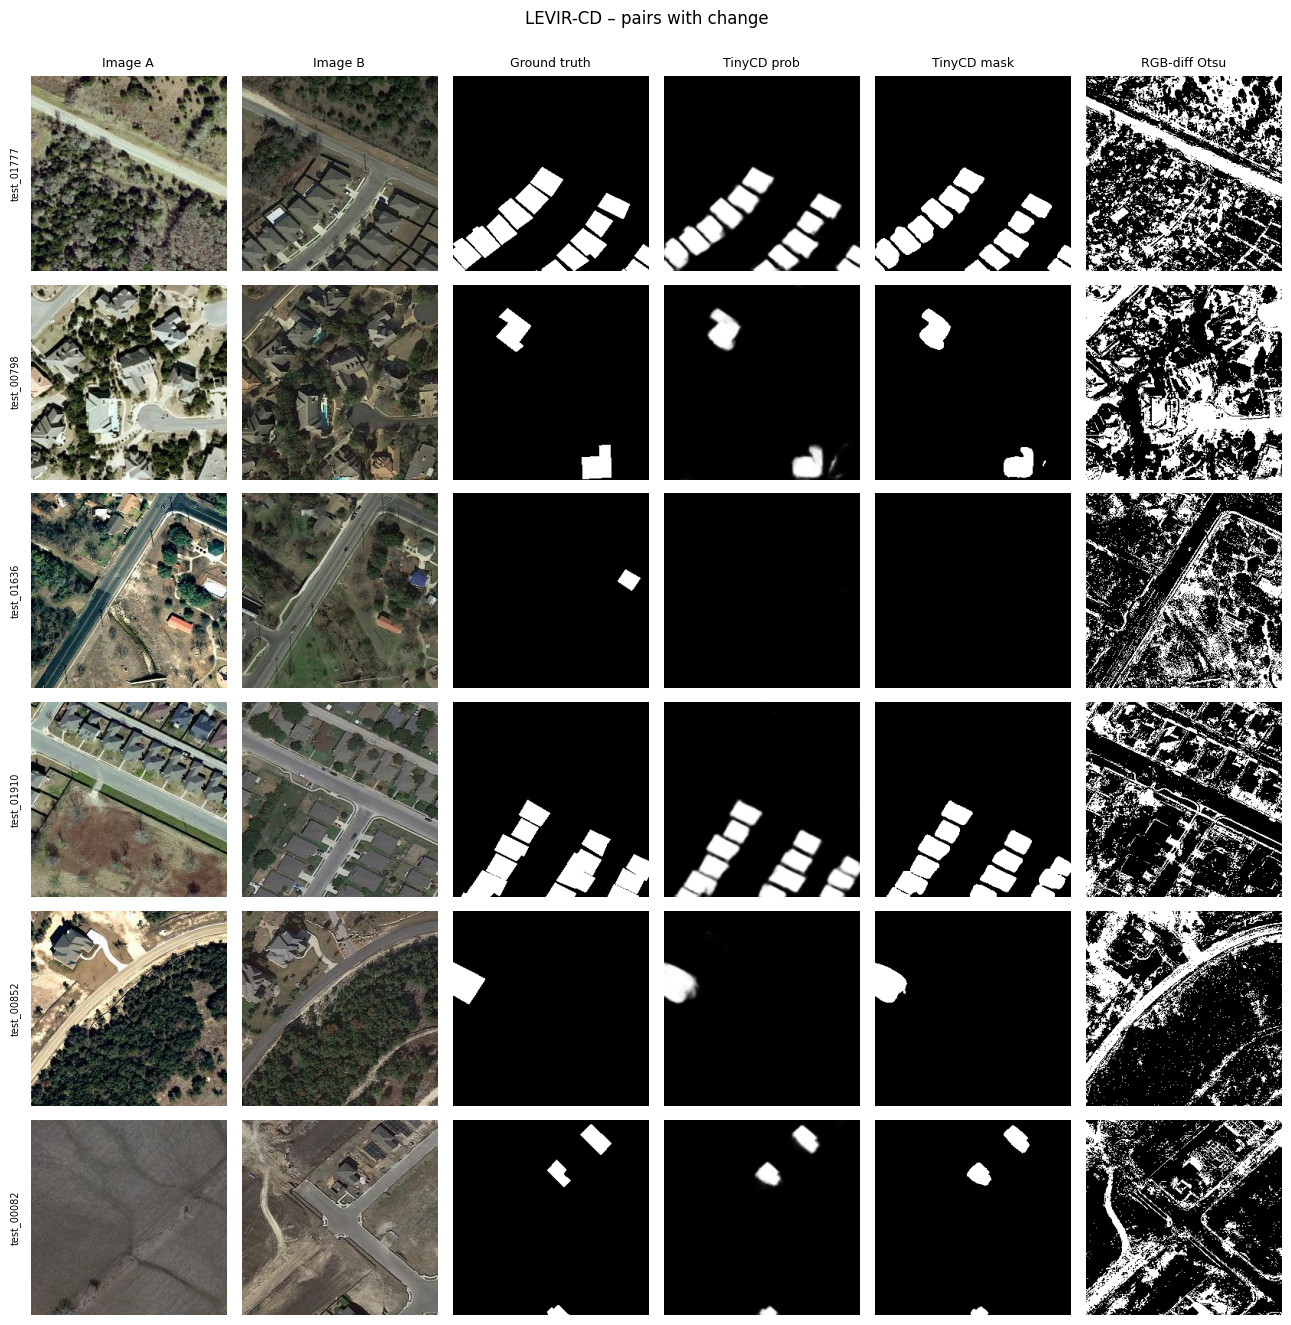

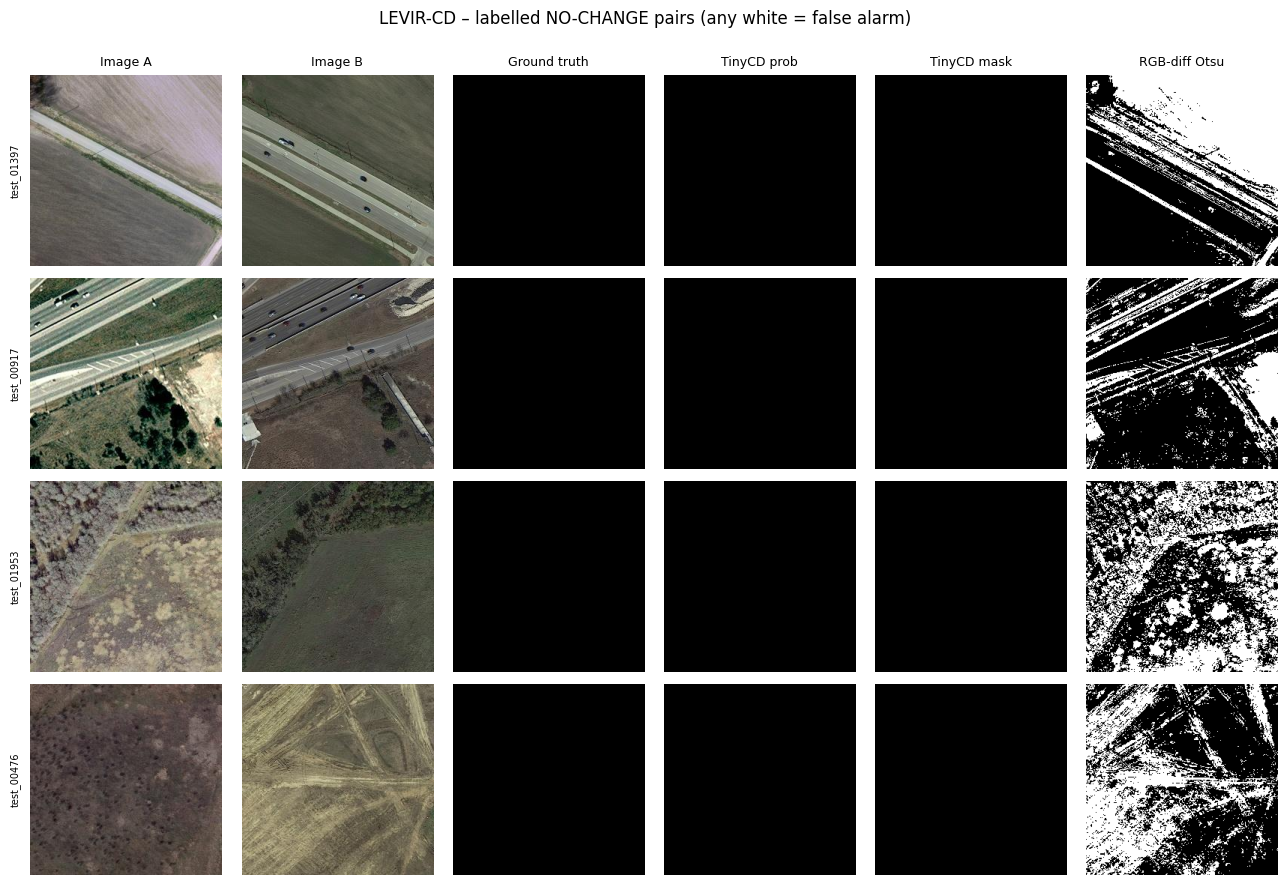

In [6]:
def show(res, title, idxs):
    cols = ['Image A','Image B','Ground truth','TinyCD prob','TinyCD mask','RGB-diff Otsu']
    fig, ax = plt.subplots(len(idxs), 6, figsize=(13, 2.2*len(idxs)))
    for r_i, i in enumerate(idxs):
        r = res[i]
        ims = [r['a'], r['b'], r['gt'], r['prob'], r['tiny'], r['otsu']]
        for c_i, im in enumerate(ims):
            ax[r_i, c_i].imshow(im, cmap=None if c_i < 2 else 'gray', vmin=0, vmax=1 if c_i >= 2 else None)
            ax[r_i, c_i].axis('off')
            if r_i == 0: ax[r_i, c_i].set_title(cols[c_i], fontsize=9)
        ax[r_i, 0].text(-0.05, 0.5, r['name'].replace('.png',''), transform=ax[r_i,0].transAxes, rotation=90, va='center', ha='right', fontsize=7)
    fig.suptitle(title, y=1.0); plt.tight_layout(); plt.show()

lev = RES['LEVIR-CD (in-domain)']
changed = [i for i, r in enumerate(lev) if r['gt'].any()]
nochange = [i for i, r in enumerate(lev) if not r['gt'].any()]
show(lev, 'LEVIR-CD – pairs with change', changed[:6])
show(lev, 'LEVIR-CD – labelled NO-CHANGE pairs (any white = false alarm)', nochange[:4])

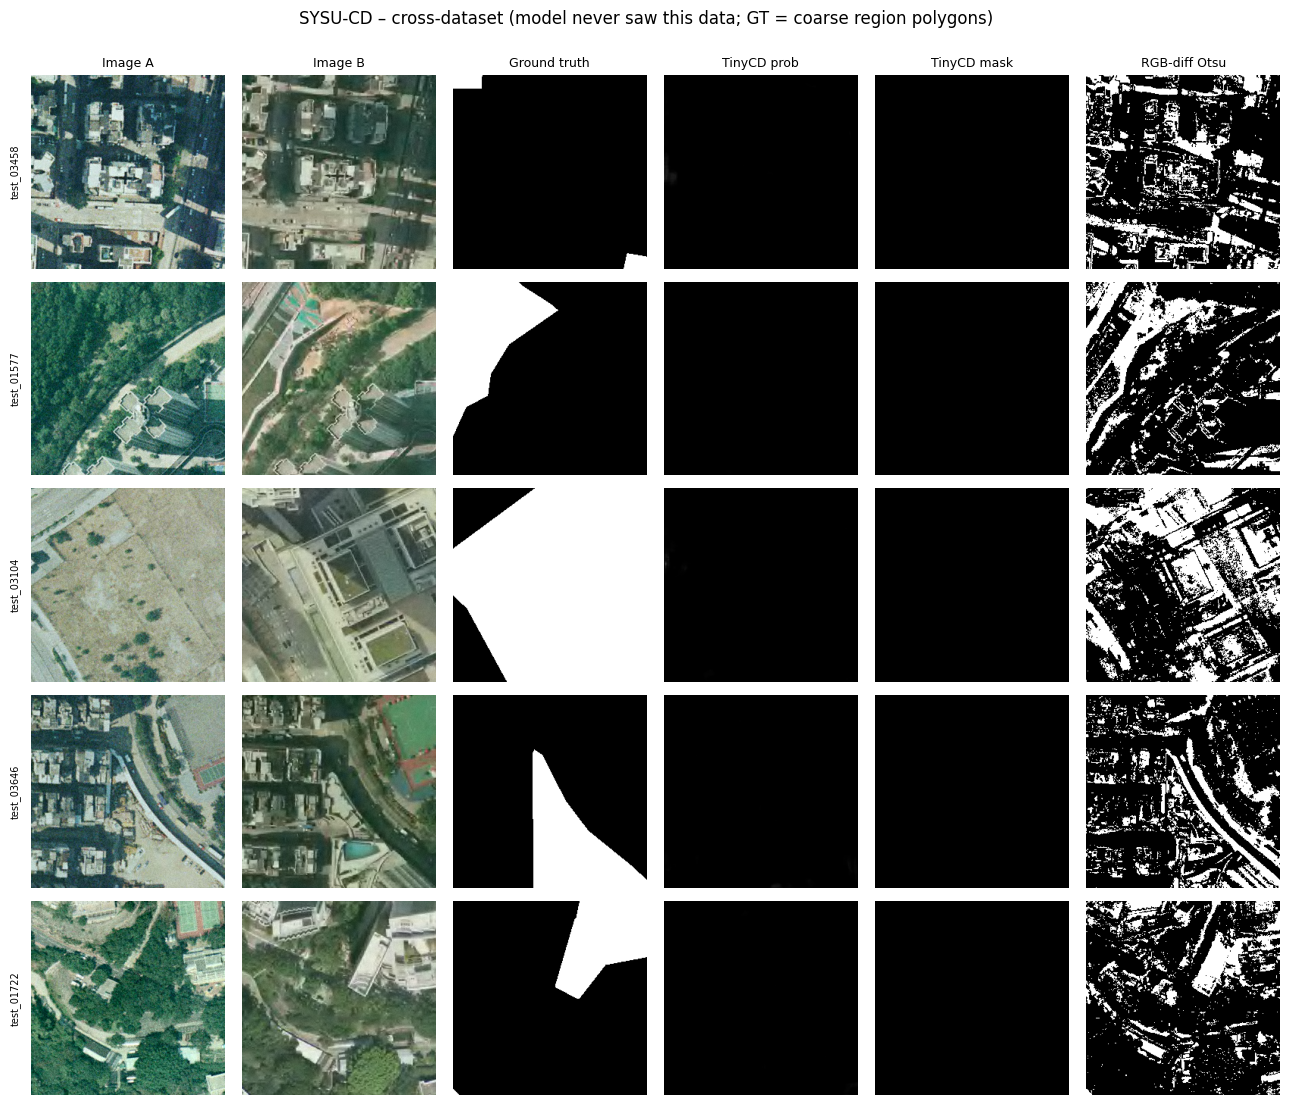

In [7]:
show(RES['SYSU-CD (cross-dataset)'], 'SYSU-CD – cross-dataset (model never saw this data; GT = coarse region polygons)', list(range(5)))

## 7. Try your own pair
Images must be the **same size and registered**; TinyCD was trained on 256×256 aerial tiles, so large images should be cropped or tiled into 256×256 pieces first (no tiling helper is included).

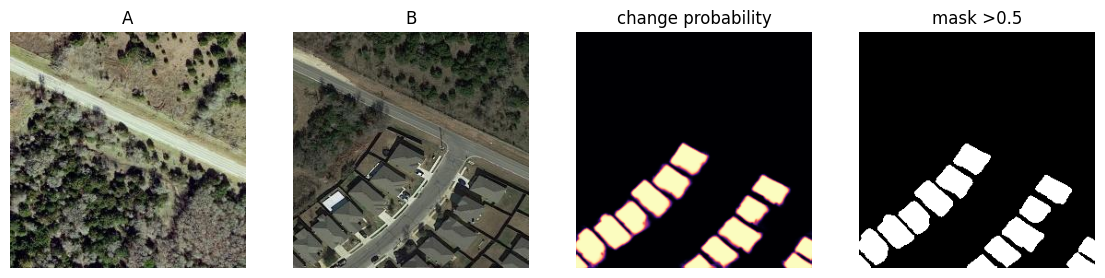

30.3 ms


In [8]:
def compare(path_a, path_b):
    a, b = C.read_rgb(path_a), C.read_rgb(path_b)
    assert a.shape == b.shape, 'images must have identical size'
    h, w = a.shape[:2]; assert h % 8 == 0 and w % 8 == 0, 'crop/pad to a multiple of 8'
    t = time.perf_counter(); p = C.predict_prob(model, a, b, device); ms = (time.perf_counter()-t)*1000
    fig, ax = plt.subplots(1, 4, figsize=(14, 3.6))
    for x, im, t_ in zip(ax, [a, b, p, p > 0.5], ['A','B','change probability','mask >0.5']): x.imshow(im, cmap=None if t_ in 'AB' else 'magma' if 'prob' in t_ else 'gray'); x.set_title(t_); x.axis('off')
    plt.show(); print(f'{ms:.1f} ms')
# example:
n = SETS['LEVIR-CD (in-domain)'][0][0]
compare(ROOT/'samples'/'levir'/'A'/n, ROOT/'samples'/'levir'/'B'/n)

## 8. Reference numbers (not recomputed here)
Measured earlier with `scripts/evaluate.py` on this machine (GTX 1080 Ti), official threshold 0.5, full test sets:

| Setting | Pairs | Precision | Recall | F1 | IoU | Notes |
|---|---|---|---|---|---|---|
| Paper, LEVIR-CD test | 2048 | 92.68 | 89.47 | 91.05 | 83.57 | published |
| **Reproduced**, official `test_ondata.py`, LEVIR-CD test | 2048 | 92.65 | 89.54 | **91.07** | 83.60 | `results/logs/official_test_levir_on_levir.log` |
| New experiment: LEVIR checkpoint → SYSU-CD test | 4000 | 82.2 | 0.16 | 0.31 | 0.16 | cross-dataset; near-total miss, see README |

The WHU-CD reproduction was **not** done: the official WHU page blocks scripted access and the authors' pre-processed copy (random 5947/743/744 split) sits in a Google Drive folder that returned HTTP 401.